# Итоговая оценка на тестовой выборке

## Импорты и окружение

In [1]:
import json
import sys
from pathlib import Path

PROJECT = Path.cwd().parent
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))

import joblib
import numpy as np
import pandas as pd

from src import experiments
from src import metrics

pd.set_option("display.width", 200)

## Данные и модель

In [2]:
data = experiments.load_from_csv(PROJECT / "data" / "incoming" / "history.csv")
df, y = experiments.prepare(data)
n_train = experiments.train_size(len(df))

train = df.iloc[:n_train]
test = df.iloc[n_train:].reset_index(drop=True)
y_train = y[:n_train]
y_test = y[n_train:]

model = joblib.load(PROJECT / "models" / "model_v1.joblib")
prob = model.predict_proba(test[experiments.FEATURES])[:, 1]

description = json.loads((PROJECT / "models" / "model_v1.json").read_text(encoding="utf-8"))

print(f"записей после очистки: {len(df)}")
print(f"обучающая часть: {n_train}, доля негатива {y_train.mean():.4f}")
print(f"тестовая часть: {len(test)}, доля негатива {y_test.mean():.4f}")
print(f"период тестовой части: {test['review_dttm'].min():%Y-%m-%d} .. {test['review_dttm'].max():%Y-%m-%d}")
print(f"модель: {description['model_version']}, запуск {description['run_id']}, "
      f"обучена на {description['n_train']} записях")

записей после очистки: 32902
обучающая часть: 26321, доля негатива 0.3738
тестовая часть: 6581, доля негатива 0.3405
период тестовой части: 2025-05-04 .. 2025-06-16
модель: v1, запуск 20261120T092938-fa0a86, обучена на 26321 записях


## Метрики модели и базового решения на тестовой выборке

In [3]:
median_len = float(train["review_text"].str.len().median())
test_len = test["review_text"].str.len().to_numpy()

majority = np.full(len(y_test), float(y_train.mean()))
length_rule = (test_len > median_len).astype(float)

predictions = {
    "Наиболее частый класс": majority,
    "Правило длины отзыва": length_rule,
    "Логистическая регрессия": prob,
}

rows = []
for name, values in predictions.items():
    scores = metrics.evaluate(y_test, values)
    rows.append(
        {
            "Модель": name,
            "ROC-AUC": scores["roc_auc"],
            "PR-AUC": scores["pr_auc"],
            "Точность": scores["precision"],
            "Полнота": scores["recall"],
            "F2-мера": scores["f2"],
            "Доля верных ответов": float(np.mean((values >= 0.5) == y_test)),
        }
    )

table = pd.DataFrame(rows).set_index("Модель").round(4)
table

,ROC-AUC,PR-AUC,Точность,Полнота,F2-мера,Доля верных ответов
Модель,,,,,,
Наиболее частый класс,0.5000,0.3405,0.0000,0.0000,0.0000,0.6595
Правило длины отзыва,0.6301,0.4179,0.4510,0.7006,0.6308,0.6077
Логистическая регрессия,0.9967,0.9938,0.9635,0.9781,0.9752,0.9799


## Доверительные интервалы методом бутстрепа

In [4]:
rng = np.random.default_rng(42)
keys = ["roc_auc", "pr_auc", "precision", "recall", "f2", "brier"]
samples = {key: [] for key in keys}

for _ in range(1000):
    index = rng.integers(0, len(y_test), len(y_test))
    if len(np.unique(y_test[index])) < 2:
        continue
    scores = metrics.evaluate(y_test[index], prob[index])
    for key in keys:
        samples[key].append(scores[key])

names = {
    "roc_auc": "ROC-AUC",
    "pr_auc": "PR-AUC",
    "precision": "Точность",
    "recall": "Полнота",
    "f2": "F2-мера",
    "brier": "Brier Score",
}

final_scores = metrics.evaluate(y_test, prob)
intervals = pd.DataFrame(
    {
        "Метрика": [names[key] for key in keys],
        "Значение": [final_scores[key] for key in keys],
        "Нижняя граница": [np.percentile(samples[key], 2.5) for key in keys],
        "Верхняя граница": [np.percentile(samples[key], 97.5) for key in keys],
    }
).set_index("Метрика").round(4)
intervals

,Значение,Нижняя граница,Верхняя граница
Метрика,,,
ROC-AUC,0.9967,0.9955,0.9978
PR-AUC,0.9938,0.9917,0.9957
Точность,0.9635,0.9562,0.9706
Полнота,0.9781,0.9724,0.9841
F2-мера,0.9752,0.9704,0.9802
Brier Score,0.0170,0.0149,0.0190


## Сравнение с оценкой по кросс-валидации

In [5]:
log_path = PROJECT / "experiments" / "log.jsonl"
entries = [json.loads(line) for line in log_path.read_text(encoding="utf-8").splitlines() if line.strip()]
run_entry = next(entry for entry in entries if entry["run_id"] == description["run_id"])

cv_info = description["cv"]
print(f"схема кросс-валидации: {cv_info['scheme']}, блоков {cv_info['n_splits']}, тестовая доля {cv_info['test_size']}")

cv_scores = {
    "ROC-AUC": (run_entry["roc_auc_mean"], run_entry["roc_auc_std"]),
    "PR-AUC": (run_entry["pr_auc_mean"], run_entry["pr_auc_std"]),
    "F2-мера": (run_entry["f2_mean"], run_entry["f2_std"]),
    "Brier Score": (run_entry["brier_mean"], run_entry["brier_std"]),
}
test_scores = metrics.evaluate(y_test, prob)
keys_by_name = {"ROC-AUC": "roc_auc", "PR-AUC": "pr_auc", "F2-мера": "f2", "Brier Score": "brier"}

comparison = pd.DataFrame(
    [
        {
            "Метрика": name,
            "Кросс-валидация": mean,
            "Отклонение по блокам": std,
            "Тестовая выборка": test_scores[keys_by_name[name]],
            "Разность": test_scores[keys_by_name[name]] - mean,
        }
        for name, (mean, std) in cv_scores.items()
    ]
).set_index("Метрика").round(4)
comparison

схема кросс-валидации: TimeSeriesSplit, блоков 5, тестовая доля 0.2


,Кросс-валидация,Отклонение по блокам,Тестовая выборка,Разность
Метрика,,,,
ROC-AUC,0.9955,0.0021,0.9967,0.0013
PR-AUC,0.9914,0.0025,0.9938,0.0024
F2-мера,0.9734,0.0051,0.9752,0.0017
Brier Score,0.0210,0.0056,0.0170,-0.0040


## Значимость различия двух лучших моделей

In [6]:
from src import models

best_by_family = {}
for entry in entries:
    family = entry["family"]
    if family not in best_by_family or entry["roc_auc_mean"] > best_by_family[family]["roc_auc_mean"]:
        best_by_family[family] = entry

top_two = sorted(best_by_family.values(), key=lambda entry: entry["roc_auc_mean"], reverse=True)[:2]
[(entry["family"], entry["params"], round(entry["roc_auc_mean"], 4)) for entry in top_two]

[('logistic_regression', {'C': 10.0, 'l1_ratio': 0.0}, 0.9955),
 ('naive_bayes', {'alpha': 0.1}, 0.9947)]

In [7]:
probability = {description["family"]: prob}

for entry in top_two:
    if entry["family"] in probability:
        continue
    pipeline = models.make_pipeline(
        entry["family"],
        text_repr=entry["text_repr"],
        use_numeric=entry["use_numeric"],
        **entry["params"],
    )
    pipeline.fit(train[experiments.FEATURES], y_train)
    probability[entry["family"]] = pipeline.predict_proba(test[experiments.FEATURES])[:, 1]

first, second = top_two[0]["family"], top_two[1]["family"]

pd.DataFrame(
    [
        {
            "Модель": first,
            "ROC-AUC на кросс-валидации": top_two[0]["roc_auc_mean"],
            "ROC-AUC на тестовой выборке": metrics.evaluate(y_test, probability[first])["roc_auc"],
        },
        {
            "Модель": second,
            "ROC-AUC на кросс-валидации": top_two[1]["roc_auc_mean"],
            "ROC-AUC на тестовой выборке": metrics.evaluate(y_test, probability[second])["roc_auc"],
        },
    ]
).set_index("Модель").round(4)

,ROC-AUC на кросс-валидации,ROC-AUC на тестовой выборке
Модель,,
logistic_regression,0.9955,0.9967
naive_bayes,0.9947,0.9940


In [8]:
rng_pair = np.random.default_rng(42)
pair_keys = ["roc_auc", "pr_auc", "f2"]
pair_samples = {key: [] for key in pair_keys}

for _ in range(1000):
    index = rng_pair.integers(0, len(y_test), len(y_test))
    if len(np.unique(y_test[index])) < 2:
        continue
    first_scores = metrics.evaluate(y_test[index], probability[first][index])
    second_scores = metrics.evaluate(y_test[index], probability[second][index])
    for key in pair_keys:
        pair_samples[key].append(first_scores[key] - second_scores[key])

first_scores = metrics.evaluate(y_test, probability[first])
second_scores = metrics.evaluate(y_test, probability[second])

significance = pd.DataFrame(
    [
        {
            "Метрика": names[key],
            "Различие": first_scores[key] - second_scores[key],
            "Нижняя граница": np.percentile(pair_samples[key], 2.5),
            "Верхняя граница": np.percentile(pair_samples[key], 97.5),
            "Доля выборок, где различие не больше нуля": float(np.mean(np.asarray(pair_samples[key]) <= 0)),
        }
        for key in pair_keys
    ]
).set_index("Метрика").round(4)
significance

,Различие,Нижняя граница,Верхняя граница,"Доля выборок, где различие не больше нуля"
Метрика,,,,
ROC-AUC,0.0028,0.0019,0.0036,0.0
PR-AUC,0.0067,0.0045,0.0089,0.0
F2-мера,0.0109,0.0055,0.0162,0.0


## Диагностика и выбор порога

### ROC-кривая, кривая «точность – полнота» и ожидаемые потери

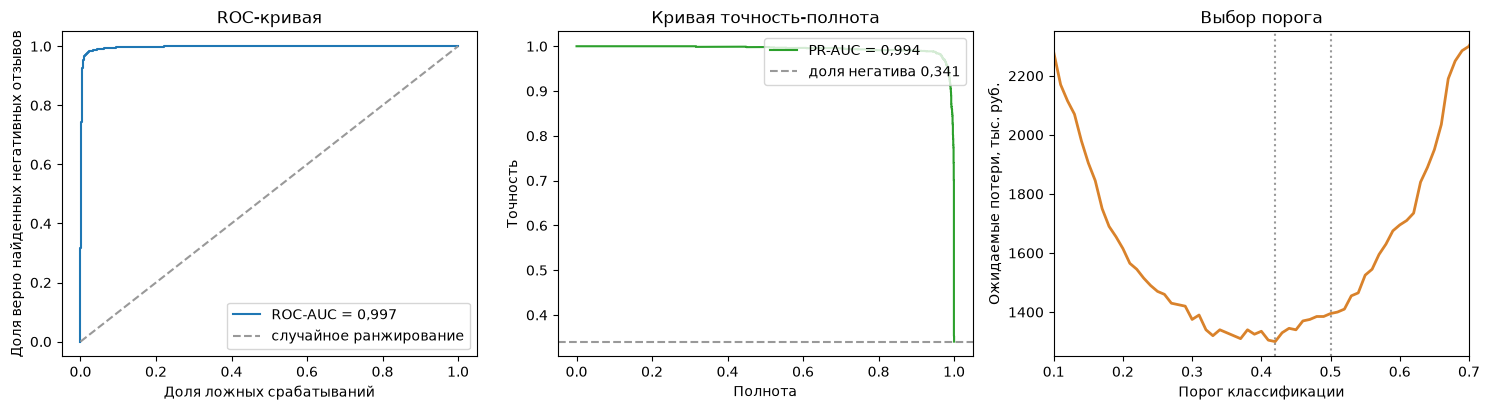

In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, roc_curve

FIGURES_DIR = PROJECT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

cost_fp = 5_000
cost_fn = 20_000

test_scores = metrics.evaluate(y_test, prob)
share = float(y_test.mean())

thresholds = np.round(np.arange(0.01, 1.0, 0.01), 2)
negatives = y_test.astype(bool)
positives = ~negatives

loss_rows = []
for threshold in thresholds:
    predicted = prob >= threshold
    false_positive = int((predicted & positives).sum())
    false_negative = int((~predicted & negatives).sum())
    loss_rows.append(
        {
            "Порог": threshold,
            "Ложных срабатываний": false_positive,
            "Пропусков": false_negative,
            "Ожидаемые потери, руб.": false_negative * cost_fn + false_positive * cost_fp,
        }
    )

losses = pd.DataFrame(loss_rows)
chosen_threshold = float(losses.loc[losses["Ожидаемые потери, руб."].idxmin(), "Порог"])

fpr, tpr, _ = roc_curve(y_test, prob)
precision, recall, _ = precision_recall_curve(y_test, prob)

figure, axes = plt.subplots(1, 3, figsize=(15, 4.2))

axes[0].plot(fpr, tpr, color="#1f77b4", label=f"ROC-AUC = {test_scores['roc_auc']:.3f}".replace(".", ","))
axes[0].plot([0, 1], [0, 1], linestyle="--", color="#999999", label="случайное ранжирование")
axes[0].set_xlabel("Доля ложных срабатываний")
axes[0].set_ylabel("Доля верно найденных негативных отзывов")
axes[0].set_title("ROC-кривая")
axes[0].legend(loc="lower right")

axes[1].plot(recall, precision, color="#2ca02c", label=f"PR-AUC = {test_scores['pr_auc']:.3f}".replace(".", ","))
axes[1].axhline(share, linestyle="--", color="#999999", label=f"доля негатива {share:.3f}".replace(".", ","))
axes[1].set_xlabel("Полнота")
axes[1].set_ylabel("Точность")
axes[1].set_title("Кривая точность-полнота")
axes[1].legend(loc="upper right")

axes[2].plot(losses["Порог"], losses["Ожидаемые потери, руб."] / 1000, color="#d9822b", linewidth=2)
axes[2].axvline(chosen_threshold, color="#999999", linestyle=":", linewidth=1.5)
axes[2].axvline(0.5, color="#999999", linestyle=":", linewidth=1.5)
axes[2].set_xlim(0.1, 0.7)
axes[2].set_ylim(1250, 2350)
axes[2].set_xlabel("Порог классификации")
axes[2].set_ylabel("Ожидаемые потери, тыс. руб.")
axes[2].set_title("Выбор порога")

figure.tight_layout()
figure.savefig(FIGURES_DIR / "diagnostics.png", dpi=150)

### Чувствительность порога к цене ошибок

In [10]:
ratio_rows = []
for ratio in (1, 2, 4, 8, 10):
    candidate = losses["Пропусков"] * ratio + losses["Ложных срабатываний"]
    index = candidate.idxmin()
    ratio_rows.append(
        {
            "Отношение цены пропуска к цене ложного срабатывания": ratio,
            "Порог": losses.loc[index, "Порог"],
            "Ложных срабатываний": losses.loc[index, "Ложных срабатываний"],
            "Пропусков": losses.loc[index, "Пропусков"],
        }
    )

sensitivity = pd.DataFrame(ratio_rows).set_index(
    "Отношение цены пропуска к цене ложного срабатывания"
).round(4)
sensitivity

,Порог,Ложных срабатываний,Пропусков
Отношение цены пропуска к цене ложного срабатывания,,,
1,0.62,43,76
2,0.51,80,50
4,0.42,104,39
8,0.30,167,27
10,0.21,237,19


### Сравнение стандартного и выбранного порога

,Точность,Полнота,F2-мера,Ложных срабатываний,Пропусков,"Ожидаемые потери, тыс. руб."
Порог,,,,,,
0.50,0.9635,0.9781,0.9752,83,49,1395.0
0.42,0.9549,0.9826,0.9769,104,39,1300.0


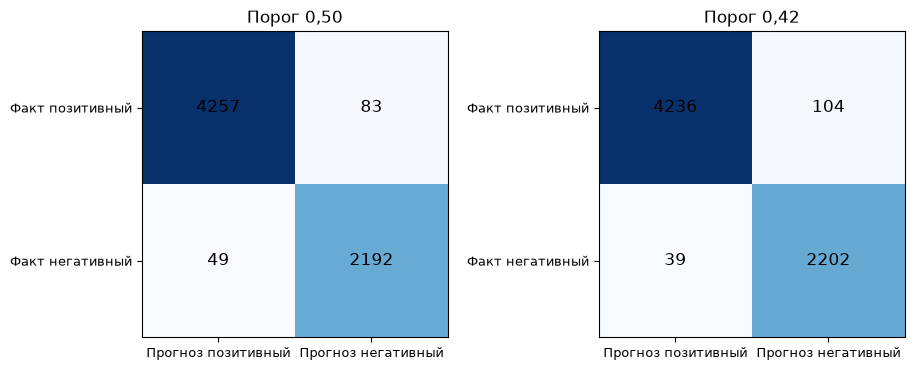

In [11]:
def confusion(y_true, y_prob, threshold):
    predicted = (np.asarray(y_prob) >= threshold).astype(int)
    y_true = np.asarray(y_true).astype(int)
    return {
        "TN": int(((predicted == 0) & (y_true == 0)).sum()),
        "FP": int(((predicted == 1) & (y_true == 0)).sum()),
        "FN": int(((predicted == 0) & (y_true == 1)).sum()),
        "TP": int(((predicted == 1) & (y_true == 1)).sum()),
    }


def confusion_frame(y_true, y_prob, threshold):
    counts = confusion(y_true, y_prob, threshold)
    return pd.DataFrame(
        [[counts["TN"], counts["FP"]], [counts["FN"], counts["TP"]]],
        index=["Факт позитивный", "Факт негативный"],
        columns=["Прогноз позитивный", "Прогноз негативный"],
    )


rows = []
for threshold in (0.5, chosen_threshold):
    scores = metrics.evaluate(y_test, prob, threshold=threshold)
    counts = confusion(y_test, prob, threshold)
    rows.append(
        {
            "Порог": threshold,
            "Точность": scores["precision"],
            "Полнота": scores["recall"],
            "F2-мера": scores["f2"],
            "Ложных срабатываний": counts["FP"],
            "Пропусков": counts["FN"],
            "Ожидаемые потери, тыс. руб.": (counts["FN"] * cost_fn + counts["FP"] * cost_fp) / 1000,
        }
    )

comparison = pd.DataFrame(rows).set_index("Порог").round(4)

figure, axes = plt.subplots(1, 2, figsize=(9.5, 3.8))
for axis, threshold in zip(axes, (0.5, chosen_threshold)):
    matrix = confusion_frame(y_test, prob, threshold)
    axis.imshow(matrix.to_numpy(), cmap="Blues")
    for row in range(2):
        for column in range(2):
            axis.text(column, row, matrix.iat[row, column], ha="center", va="center", fontsize=12)
    axis.set_xticks([0, 1], matrix.columns, fontsize=9)
    axis.set_yticks([0, 1], matrix.index, fontsize=9)
    axis.set_title(f"Порог {threshold:.2f}".replace(".", ","))
    axis.grid(False)
figure.tight_layout()
figure.savefig(FIGURES_DIR / "confusion_matrices_compare.png", dpi=150)
comparison

## Анализ ошибок по срезам

### Срезы по источнику отзыва

In [12]:
from sklearn.metrics import fbeta_score, precision_score, recall_score

MIN_SLICE = 50


def slice_metrics(name, mask, threshold=chosen_threshold):
    truth = np.asarray(y_test)[mask]
    values = np.asarray(prob)[mask]
    predicted = (values >= threshold).astype(int)
    counts = confusion(truth, values, threshold)
    both_classes = len(np.unique(truth)) == 2
    scores = metrics.evaluate(truth, values) if both_classes else {}
    return {
        "Срез": name,
        "Записей": int(truth.size),
        "Доля негатива": float(truth.mean()),
        "ROC-AUC": scores.get("roc_auc", np.nan),
        "PR-AUC": scores.get("pr_auc", np.nan),
        "Точность": float(precision_score(truth, predicted, zero_division=0)),
        "Полнота": float(recall_score(truth, predicted, zero_division=0)),
        "F2-мера": float(fbeta_score(truth, predicted, beta=2, zero_division=0)),
        "Ложных срабатываний": counts["FP"],
        "Пропусков": counts["FN"],
        "Доля ошибок": float(np.mean(predicted != truth)),
    }


source_counts = test["review_source"].value_counts()
main_sources = list(source_counts[source_counts >= MIN_SLICE].index)
is_main = test["review_source"].isin(main_sources)

source_rows = [slice_metrics(name, (test["review_source"] == name).to_numpy()) for name in main_sources]
source_rows.append(slice_metrics("Прочие площадки", (~is_main).to_numpy()))

slices_by_source = pd.DataFrame(source_rows).set_index("Срез").round(4)
slices_by_source

,Записей,Доля негатива,ROC-AUC,PR-AUC,Точность,Полнота,F2-мера,Ложных срабатываний,Пропусков,Доля ошибок
Срез,,,,,,,,,,
banki.ru,5943,0.3118,0.9965,0.9925,0.9498,0.9806,0.9743,96,36,0.0222
sravni.ru,196,0.1837,0.9983,0.9934,0.9706,0.9167,0.9270,1,3,0.0204
пульс,114,1.0000,NaN,NaN,1.0000,1.0000,1.0000,0,0,0.0000
otzovik,96,0.7708,0.9539,0.9841,0.9136,1.0000,0.9814,7,0,0.0729
asn,68,0.0294,1.0000,1.0000,1.0000,1.0000,1.0000,0,0,0.0000
пикабу,54,1.0000,NaN,NaN,1.0000,1.0000,1.0000,0,0,0.0000
Прочие площадки,110,0.9818,1.0000,1.0000,1.0000,1.0000,1.0000,0,0,0.0000


### Срезы по длине отзыва

In [13]:
length = test["review_text"].str.len()
length_bins = [0, 200, 500, 1000, np.inf]
length_labels = ["до 200", "200–500", "500–1000", "свыше 1000"]
length_groups = pd.cut(length, bins=length_bins, labels=length_labels, right=False)

length_rows = [slice_metrics(label, (length_groups == label).to_numpy()) for label in length_labels]
slices_by_length = pd.DataFrame(length_rows).set_index("Срез").round(4)
slices_by_length

,Записей,Доля негатива,ROC-AUC,PR-AUC,Точность,Полнота,F2-мера,Ложных срабатываний,Пропусков,Доля ошибок
Срез,,,,,,,,,,
до 200,254,0.7953,0.9986,0.9996,0.9949,0.9752,0.9791,1,5,0.0236
200–500,3324,0.1772,0.9968,0.9927,0.9443,0.9779,0.9710,34,13,0.0141
500–1000,1969,0.3687,0.9956,0.9914,0.9429,0.9780,0.9707,43,16,0.0300
свыше 1000,1034,0.7002,0.9894,0.9946,0.9651,0.9931,0.9874,26,5,0.0300


## Интерпретация модели

### Перестановочная важность признаков

In [14]:
from sklearn.inspection import permutation_importance

baseline_roc_auc = metrics.evaluate(y_test, prob)["roc_auc"]
permutation = permutation_importance(
    model,
    test[experiments.FEATURES],
    y_test,
    scoring="roc_auc",
    n_repeats=20,
    random_state=42,
    n_jobs=1,
)

permutation_frame = pd.DataFrame(
    {
        "Признак": experiments.FEATURES,
        "ROC-AUC при перемешивании": baseline_roc_auc - permutation.importances_mean,
        "Падение ROC-AUC": permutation.importances_mean,
        "Стандартное отклонение": permutation.importances_std,
    }
).set_index("Признак").round(4)
permutation_frame

,ROC-AUC при перемешивании,Падение ROC-AUC,Стандартное отклонение
Признак,,,
review_text,0.5310,0.4657,0.0058
review_source,0.9927,0.0040,0.0006


### Веса признаков модели

In [15]:
from IPython.display import display

weights = models.coefficients(model)

word_weights = pd.DataFrame(
    [(name.removeprefix("text__"), weight) for name, weight in weights if name.startswith("text__")],
    columns=["Слово или биграмма", "Вес"],
)
source_weights = pd.DataFrame(
    [
        ("источник: " + name.removeprefix("source__review_source_"), weight)
        for name, weight in weights
        if name.startswith("source__review_source_")
    ],
    columns=["Признак", "Вес"],
)
numeric_weights = pd.DataFrame(
    [(name.removeprefix("num__"), weight) for name, weight in weights if name.startswith("num__")],
    columns=["Признак", "Вес"],
)

toward_negative = word_weights.nlargest(12, "Вес").round(4).reset_index(drop=True)
toward_positive = word_weights.nsmallest(12, "Вес").round(4).reset_index(drop=True)

display(toward_negative)
display(toward_positive)
display(source_weights.head(8).round(4).reset_index(drop=True))
numeric_weights.round(4).reset_index(drop=True)

,Слово или биграмма,Вес
0,не,11.4738
1,прошу,9.6669
2,не рекомендую,7.2685
3,заблокировали,6.3781
4,здравствуйте,6.0806
5,не советую,5.9843
6,почему,5.8521
7,зачем,5.7386
8,ответ,5.6642
9,нет,5.4116


,Слово или биграмма,Вес
0,спасибо,-21.2740
1,быстро,-14.9096
2,вернули,-10.2746
3,очень,-10.2349
4,приятно,-9.5870
5,оперативно,-9.4806
6,благодарю,-9.2952
7,помог,-8.0698
8,благодарность,-7.9286
9,помогла,-7.6175


,Признак,Вес
0,источник: пульс,3.6626
1,источник: asn,-3.5458
2,источник: banki.ru,-2.0440
3,источник: вконтакте,1.9902
4,источник: sravni.ru,-1.9534
5,источник: пикабу,1.8744
6,источник: irecommend,-1.7094
7,источник: twitter,1.4165


,Признак,Вес
0,words_cnt,0.0848
1,avg_word_len,-0.0541
2,exclaim_cnt,-0.0208


### Частичная зависимость числовых признаков

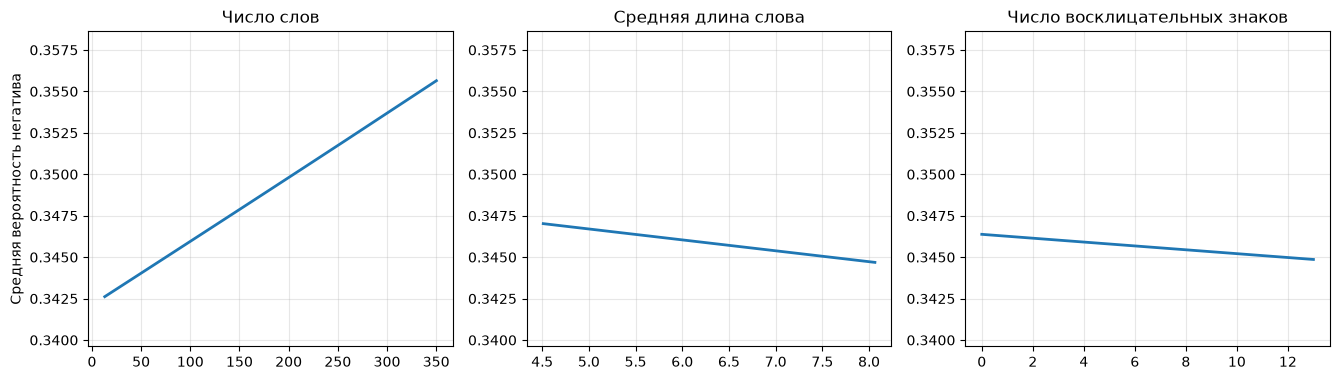

In [16]:
from scipy.special import expit

preprocessor = model.named_steps["prep"]
classifier = model.named_steps["clf"]

feature_names = list(preprocessor.get_feature_names_out())
feature_matrix = preprocessor.transform(
    model.named_steps["features"].transform(test[experiments.FEATURES])
)
coefficients = classifier.coef_.ravel()
intercept = float(classifier.intercept_[0])
logits = np.asarray(feature_matrix @ coefficients).ravel() + intercept
numeric = models.add_text_features(test[experiments.FEATURES])
scaler = preprocessor.named_transformers_["num"].named_steps["scale"]

titles = {
    "words_cnt": "Число слов",
    "avg_word_len": "Средняя длина слова",
    "exclaim_cnt": "Число восклицательных знаков",
}

curves = {}
for column in models.NUM_COLS:
    index = feature_names.index(f"num__{column}")
    position = models.NUM_COLS.index(column)
    current = feature_matrix.getcol(index).toarray().ravel()
    grid = np.percentile(numeric[column].to_numpy(dtype=float), np.linspace(1, 99, 40))
    scaled = (grid - scaler.mean_[position]) / scaler.scale_[position]
    curve = [
        float(np.mean(expit(logits - coefficients[index] * current + coefficients[index] * value)))
        for value in scaled
    ]
    curves[column] = (grid, curve)

lowest = min(min(curve) for _, curve in curves.values())
highest = max(max(curve) for _, curve in curves.values())

figure, axes = plt.subplots(1, 3, figsize=(13.5, 3.9))
for axis, column in zip(axes, models.NUM_COLS):
    grid, curve = curves[column]
    axis.plot(grid, curve, color="#1f77b4", linewidth=2)
    axis.set_title(titles[column])
    axis.set_ylim(lowest - 0.003, highest + 0.003)
    axis.grid(alpha=0.3)

axes[0].set_ylabel("Средняя вероятность негатива")
figure.tight_layout()
figure.savefig(FIGURES_DIR / "partial_dependence.png", dpi=150)

### Локальный разбор предсказаний

In [17]:
def explain(position, top=6):
    row = feature_matrix[position].toarray().ravel()
    contribution = row * coefficients
    order = np.argsort(contribution)[::-1]
    top_positive = order[:top]
    top_negative = order[-top:][::-1]

    def label(index):
        name = feature_names[index]
        if name.startswith("text__"):
            return name.removeprefix("text__")
        if name.startswith("source__review_source_"):
            return "источник: " + name.removeprefix("source__review_source_")
        return name.removeprefix("num__")

    rows = [
        {
            "Признак": label(index),
            "Значение": float(row[index]),
            "Вклад в логарифм шансов": float(contribution[index]),
        }
        for index in np.concatenate([top_positive, top_negative])
    ]
    return pd.DataFrame(rows).round(4)


def describe(position):
    actual = "негативная" if y_test[position] == 1 else "позитивная"
    return (
        f"запись {position}: площадка {test.loc[position, 'review_source']}, "
        f"дата {test.loc[position, 'review_dttm']:%Y-%m-%d}, "
        f"истинная окраска {actual}, вероятность негатива {prob[position]:.4f}, "
        f"порог {chosen_threshold:.2f}"
    )


confident = np.where((y_test == 1) & (prob >= 0.99))[0]
correct_index = int(confident[np.argmax(prob[confident])])
missed = np.where((y_test == 1) & (prob < chosen_threshold))[0]
error_index = int(missed[np.argmin(prob[missed])])

In [18]:
print(describe(correct_index))
print(str(test.loc[correct_index, "review_text"])[:400].replace("\n", " "))
explain(correct_index)

запись 3187: площадка вконтакте, дата 2025-05-24, истинная окраска негативная, вероятность негатива 1.0000, порог 0.42
Меня заблокировали 21 мая. На карте 95 тысяч рублей — мои последние средства. Обещали 22 мая разблокировать, потом сказали ждать до 23-го. Сейчас уже 24-е, и никто не звонит, не пишет. Живу далеко от Москвы, у меня нет возможности ни приехать, ни долго ждать. Почему вы молчите? Когда вы наконец объяснитесь?


,Признак,Значение,Вклад в логарифм шансов
0,источник: вконтакте,1.0000,1.9902
1,не,0.0524,0.6013
2,заблокировали,0.0921,0.5872
3,вы,0.1286,0.5456
4,пишет,0.1251,0.5051
5,почему,0.0816,0.4777
6,до 23,0.1678,-0.2019
7,95,0.1703,-0.1821
8,потом сказали,0.1901,-0.1642
9,долго ждать,0.1507,-0.0783


In [19]:
print(describe(error_index))
print(str(test.loc[error_index, "review_text"])[:400].replace("\n", " "))
explain(error_index)

запись 2103: площадка banki.ru, дата 2025-05-18, истинная окраска негативная, вероятность негатива 0.0001, порог 0.42
Сегодня, 18.05.2025, я обратилась в службу поддержки Т-Банка, мне нужна была справка об оплате лперации ха 2023 год. Сотрудник банка Полина ответила быстро и буквально через 5 минут я получила справку. Хочу выразить свою благодарность сотрудникам банка, так как я обращаюсь за помощью и мне не разу не отказали и выполняли мои просьбы , и вообще я советую Т-Банк . Очень удобное приложение, всегда ин


,Признак,Значение,Вклад в логарифм шансов
0,не,0.0467,0.5364
1,отказали,0.1125,0.4514
2,справку,0.1035,0.2521
3,2023,0.1174,0.2399
4,сегодня,0.0697,0.2294
5,справка,0.1193,0.2035
6,источник: banki.ru,1.0000,-2.0440
7,спасибо,0.0455,-0.9672
8,быстро,0.0498,-0.7432
9,благодарность,0.0717,-0.5686


## Устойчивость модели

### Виды искажений

In [20]:
ALPHABET = "абвгдеёжзийклмнопрстуфхцчшщъыьэюя"


def probabilities(frame):
    return model.predict_proba(frame[experiments.FEATURES])[:, 1]


def numeric_noise(frame, rng, share=0.10):
    features = models.add_text_features(frame[experiments.FEATURES])
    logits = np.asarray(preprocessor.transform(features) @ coefficients).ravel() + intercept
    raw = features[models.NUM_COLS].to_numpy(dtype=float)
    scaled = (raw - scaler.mean_) / scaler.scale_
    weights = np.array([coefficients[feature_names.index(f"num__{column}")] for column in models.NUM_COLS])
    noisy = scaled.copy()
    noisy[:, 0] += raw[:, 0] * rng.uniform(-share, share, len(frame)) / scaler.scale_[0]
    noisy[:, 1] += raw[:, 1] * rng.uniform(-share / 2, share / 2, len(frame)) / scaler.scale_[1]
    noisy[:, 2] += rng.choice([-1.0, 1.0], len(frame)) / scaler.scale_[2]
    return expit(logits + (noisy - scaled) @ weights)


def typos(frame, rng, share):
    def corrupt(text):
        words = str(text).split()
        for position, word in enumerate(words):
            if len(word) > 2 and rng.random() < share:
                cut = rng.integers(0, len(word))
                words[position] = word[:cut] + ALPHABET[rng.integers(0, len(ALPHABET))] + word[cut + 1:]
        return " ".join(words)

    result = frame.copy()
    result["review_text"] = [corrupt(text) for text in result["review_text"]]
    return result


def missing(frame, rng, text_share=0.0, source_share=0.0):
    result = frame.copy()
    if text_share:
        result.loc[rng.random(len(result)) < text_share, "review_text"] = ""
    if source_share:
        result.loc[rng.random(len(result)) < source_share, "review_source"] = "неизвестная площадка"
    return result

### Результаты проверки

In [21]:
rng = np.random.default_rng(42)
clean_roc_auc = metrics.evaluate(y_test, prob)["roc_auc"]

scenarios = {
    "Без искажений": prob,
    "Шум в числовых признаках 10 %": numeric_noise(test, rng),
    "Опечатки в 5 % слов": probabilities(typos(test, rng, 0.05)),
    "Опечатки в 20 % слов": probabilities(typos(test, rng, 0.20)),
    "Пустой текст у 5 % записей": probabilities(missing(test, rng, text_share=0.05)),
    "Пустой текст у 20 % записей": probabilities(missing(test, rng, text_share=0.20)),
    "Неизвестная площадка у 20 % записей": probabilities(missing(test, rng, source_share=0.20)),
    "Все искажения вместе": numeric_noise(
        missing(typos(test, rng, 0.10), rng, text_share=0.20, source_share=0.20), rng
    ),
}

rows = []
for name, values in scenarios.items():
    scores = metrics.evaluate(y_test, values, threshold=chosen_threshold)
    rows.append(
        {
            "Сценарий": name,
            "ROC-AUC": scores["roc_auc"],
            "Падение ROC-AUC": max(clean_roc_auc - scores["roc_auc"], 0.0),
            "PR-AUC": scores["pr_auc"],
            "F2-мера": scores["f2"],
            "Доля ошибок": float(np.mean((values >= chosen_threshold) != y_test)),
        }
    )

stability = pd.DataFrame(rows).set_index("Сценарий").round(4)
stability

,ROC-AUC,Падение ROC-AUC,PR-AUC,F2-мера,Доля ошибок
Сценарий,,,,,
Без искажений,0.9967,0.0000,0.9938,0.9769,0.0217
Шум в числовых признаках 10 %,0.9967,0.0000,0.9938,0.9769,0.0217
Опечатки в 5 % слов,0.9966,0.0001,0.9934,0.9755,0.0237
Опечатки в 20 % слов,0.9956,0.0011,0.9916,0.9697,0.0298
Пустой текст у 5 % записей,0.9938,0.0029,0.9869,0.9605,0.0524
Пустой текст у 20 % записей,0.9738,0.0229,0.9398,0.9116,0.1488
Неизвестная площадка у 20 % записей,0.9958,0.0010,0.9919,0.9712,0.0328
Все искажения вместе,0.9693,0.0274,0.9432,0.9088,0.1565


## Проверка данных и модели на новых порциях

### Загрузка порций

In [22]:
BATCHES_DIR = PROJECT / "data" / "incoming"
PORTION_NAMES = ["batch_01", "batch_02", "batch_03", "batch_04"]


def load_portion(name):
    features = pd.read_csv(BATCHES_DIR / "features" / f"{name}.csv")
    labels = pd.read_csv(BATCHES_DIR / "labels" / f"{name}.csv")
    features["review_dttm"] = pd.to_datetime(features["review_dttm"], errors="coerce")
    labels["review_dttm"] = pd.to_datetime(labels["review_dttm"], errors="coerce")
    return features.merge(labels, on=["id_client", "review_dttm"], how="left")


portions = {name: load_portion(name) for name in PORTION_NAMES}

overview = pd.DataFrame(
    [
        {
            "Порция": name,
            "Записей": len(frame),
            "Начало": frame["review_dttm"].min().date(),
            "Конец": frame["review_dttm"].max().date(),
            "Доля с разметкой": float(frame["review_emotion"].notna().mean()),
        }
        for name, frame in portions.items()
    ]
).set_index("Порция").round(4)
overview

,Записей,Начало,Конец,Доля с разметкой
Порция,,,,
batch_01,5710,2025-06-17,2025-07-20,1.0
batch_02,5758,2025-07-21,2025-08-25,1.0
batch_03,5636,2025-08-26,2025-10-01,1.0
batch_04,5592,2025-10-02,2025-11-05,1.0


### Функции проверки качества

In [23]:
from src import quality


def empty_or_short(frame):
    text = frame["review_text"].fillna("").astype(str).str.strip()
    return (text.str.len() < quality.MIN_TEXT_LEN).to_numpy()


def repeated_text(frame, seen):
    text = frame["review_text"].fillna("").astype(str).str.strip()
    usable = text.str.len() >= quality.MIN_TEXT_LEN
    return ((text.duplicated(keep="first") | text.isin(seen)) & usable).to_numpy()


def bad_date(frame, portion_date):
    moment = frame["review_dttm"]
    too_late = moment.isna() | (moment.dt.normalize() > portion_date)
    too_early = moment.dt.normalize() < portion_date - pd.Timedelta(days=quality.MAX_AGE_DAYS)
    return (too_late | too_early).to_numpy()


def unknown_source(frame):
    source = frame["review_source"].fillna("").astype(str).str.strip().str.lower()
    return (~source.isin(quality.SOURCES)).to_numpy()


def unknown_product(frame):
    product = frame["product"].fillna("").astype(str).str.strip().str.lower()
    return (frame["product"].notna() & ~product.isin(quality.PRODUCTS)).to_numpy()


def unknown_emotion(frame):
    emotion = frame["review_emotion"].fillna("").astype(str).str.strip()
    return (frame["review_emotion"].notna() & ~emotion.isin(quality.EMOTIONS)).to_numpy()


def quality_report(frame, portion_date, seen):
    checks = {
        "Пустой текст или короче 20 символов": empty_or_short(frame),
        "Повтор текста": repeated_text(frame, seen),
        "Дата вне допустимого диапазона": bad_date(frame, portion_date),
        "Площадка вне справочника": unknown_source(frame),
        "Продукт вне справочника": unknown_product(frame),
        "Разметка вне допустимых значений": unknown_emotion(frame),
    }
    return pd.Series({name: int(mask.sum()) for name, mask in checks.items()})

### Проверка на испорченном файле

In [24]:
history_texts = set(df["review_text"].astype(str).str.strip())
portion_date = portions["batch_01"]["review_dttm"].max().normalize()
first = portions["batch_01"]

valid = ~(
    empty_or_short(first)
    | repeated_text(first, history_texts)
    | bad_date(first, portion_date)
    | unknown_source(first)
    | unknown_product(first)
    | unknown_emotion(first)
)
demo = first[valid].head(300).copy().reset_index(drop=True)

corrupted = demo.copy()
corrupted.loc[0:2, "review_text"] = ""
corrupted.loc[3:4, "review_text"] = "Спасибо!"
corrupted.loc[5:7, "review_source"] = "мыло"
corrupted.loc[8:9, "review_dttm"] = portion_date + pd.Timedelta(days=5)
corrupted.loc[10:11, "review_dttm"] = portion_date - pd.Timedelta(days=4 * 365)
corrupted.loc[12, "review_text"] = demo.loc[20, "review_text"]
corrupted.loc[13, "review_text"] = demo.loc[21, "review_text"]
corrupted.loc[14:16, "product"] = "ипотека для марсиан"
corrupted.loc[17:18, "review_emotion"] = "Нейтральный"

corruption_demo = pd.DataFrame(
    {
        "До искажений": quality_report(demo, portion_date, history_texts),
        "После искажений": quality_report(corrupted, portion_date, history_texts),
    }
)
corruption_demo

,До искажений,После искажений
Пустой текст или короче 20 символов,0,5
Повтор текста,0,2
Дата вне допустимого диапазона,0,4
Площадка вне справочника,0,3
Продукт вне справочника,0,3
Разметка вне допустимых значений,0,2


### Проверки на реальных порциях

In [25]:
seen = set(df["review_text"].astype(str).str.strip())
clean_portions = {}
check_rows = []

for name, frame in portions.items():
    portion_date = frame["review_dttm"].max().normalize()
    report = quality_report(frame, portion_date, seen)
    mask = (
        empty_or_short(frame)
        | repeated_text(frame, seen)
        | bad_date(frame, portion_date)
        | unknown_source(frame)
        | unknown_product(frame)
        | unknown_emotion(frame)
    )
    clean_portions[name] = frame[~mask].reset_index(drop=True)
    check_rows.append(
        {
            "Порция": name,
            **report.to_dict(),
            "Карантин": int(mask.sum()),
            "Доля карантина": float(mask.mean()),
        }
    )
    seen |= set(frame["review_text"].astype(str).str.strip())

portion_checks = pd.DataFrame(check_rows).set_index("Порция").round(4)
portion_checks

,Пустой текст или короче 20 символов,Повтор текста,Дата вне допустимого диапазона,Площадка вне справочника,Продукт вне справочника,Разметка вне допустимых значений,Карантин,Доля карантина
Порция,,,,,,,,
batch_01,162,107,0,0,0,0,269,0.0471
batch_02,375,102,0,0,0,0,477,0.0828
batch_03,385,76,0,0,0,0,461,0.0818
batch_04,323,38,0,0,26,0,382,0.0683


### Качество модели по порциям

In [26]:
metric_rows = []

for name, frame in clean_portions.items():
    values = model.predict_proba(frame[experiments.FEATURES])[:, 1]
    labeled = frame["review_emotion"].notna().to_numpy()
    truth = (frame.loc[labeled, "review_emotion"].astype(str).str.strip() == "Негативный").astype(int).to_numpy()
    scores = metrics.evaluate(truth, values[labeled], threshold=chosen_threshold)
    metric_rows.append(
        {
            "Порция": name,
            "Оценено записей": int(labeled.sum()),
            "ROC-AUC": scores["roc_auc"],
            "PR-AUC": scores["pr_auc"],
            "F2-мера": scores["f2"],
            "Доля ошибок": float(np.mean((values[labeled] >= chosen_threshold) != truth)),
            "Доля негатива по прогнозу": float(np.mean(values >= chosen_threshold)),
        }
    )

portion_metrics = pd.DataFrame(metric_rows).set_index("Порция").round(4)
portion_metrics

,Оценено записей,ROC-AUC,PR-AUC,F2-мера,Доля ошибок,Доля негатива по прогнозу
Порция,,,,,,
batch_01,5441,0.9974,0.9935,0.9816,0.0186,0.3365
batch_02,5281,0.9969,0.9948,0.9786,0.0222,0.4003
batch_03,5175,0.9967,0.9931,0.9806,0.0186,0.3932
batch_04,5210,0.9959,0.9908,0.9797,0.0209,0.4102


### Стабильность признаков

In [27]:
def psi_numeric(reference, current, bins=10):
    reference = np.asarray(reference, dtype=float)
    current = np.asarray(current, dtype=float)
    edges = np.quantile(reference, np.linspace(0, 1, bins + 1))
    edges[0], edges[-1] = -np.inf, np.inf
    base_share = np.histogram(reference, bins=edges)[0] / len(reference)
    current_share = np.histogram(current, bins=edges)[0] / len(current)
    base_share = np.clip(base_share, 1e-6, None)
    current_share = np.clip(current_share, 1e-6, None)
    return float(np.sum((current_share - base_share) * np.log(current_share / base_share)))


def psi_categorical(reference, current):
    base_share = pd.Series(reference).value_counts(normalize=True)
    current_share = pd.Series(current).value_counts(normalize=True)
    categories = base_share.index.union(current_share.index)
    base_share = base_share.reindex(categories).fillna(0.0) + 1e-6
    current_share = current_share.reindex(categories).fillna(0.0) + 1e-6
    return float(np.sum((current_share - base_share) * np.log(current_share / base_share)))


train_features = models.add_text_features(train[experiments.FEATURES])
train_scores = model.predict_proba(train[experiments.FEATURES])[:, 1]

psi_rows = []
for name, frame in clean_portions.items():
    features = models.add_text_features(frame[experiments.FEATURES])
    values = model.predict_proba(frame[experiments.FEATURES])[:, 1]
    psi_rows.append(
        {
            "Порция": name,
            "Число слов": psi_numeric(train_features["words_cnt"], features["words_cnt"]),
            "Средняя длина слова": psi_numeric(train_features["avg_word_len"], features["avg_word_len"]),
            "Восклицательные знаки": psi_numeric(train_features["exclaim_cnt"], features["exclaim_cnt"]),
            "Площадка": psi_categorical(train["review_source"], frame["review_source"]),
            "Прогноз": psi_numeric(train_scores, values),
        }
    )

psi_table = pd.DataFrame(psi_rows).set_index("Порция").round(4)
psi_table

,Число слов,Средняя длина слова,Восклицательные знаки,Площадка,Прогноз
Порция,,,,,
batch_01,0.0106,0.0121,0.0027,0.0146,0.0350
batch_02,0.0041,0.0046,0.0031,0.0275,0.0359
batch_03,0.0168,0.0051,0.0009,0.0443,0.0301
batch_04,0.0287,0.0060,0.0025,0.1105,0.0321


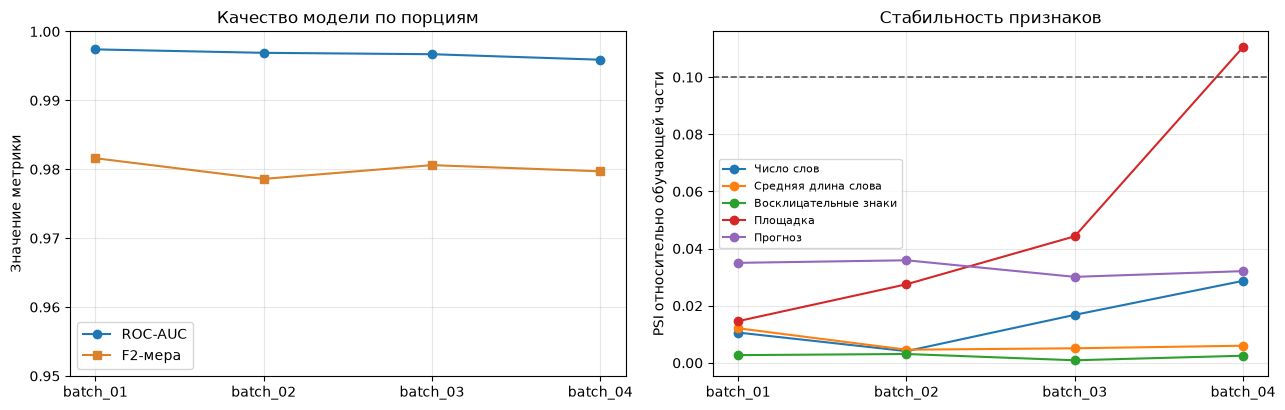

In [28]:
figure, axes = plt.subplots(1, 2, figsize=(13, 4.2))
positions = np.arange(len(portion_metrics))

axes[0].plot(positions, portion_metrics["ROC-AUC"], marker="o", color="#1f77b4", label="ROC-AUC")
axes[0].plot(positions, portion_metrics["F2-мера"], marker="s", color="#d9822b", label="F2-мера")
axes[0].set_xticks(positions, portion_metrics.index)
axes[0].set_ylim(0.95, 1.0)
axes[0].set_ylabel("Значение метрики")
axes[0].set_title("Качество модели по порциям")
axes[0].grid(alpha=0.3)
axes[0].legend()

for column in psi_table.columns:
    axes[1].plot(positions, psi_table[column], marker="o", label=column)
axes[1].axhline(0.1, color="#555555", linestyle="--", linewidth=1.2)
axes[1].set_xticks(positions, psi_table.index)
axes[1].set_ylabel("PSI относительно обучающей части")
axes[1].set_title("Стабильность признаков")
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=8)

figure.tight_layout()
figure.savefig(FIGURES_DIR / "portions.png", dpi=150)